# 04 - Boosting

Trains AdaBoost, Gradient Boosting, and HistGradientBoosting on `Social_Network_Ads.csv` using the same target/split as the classification module, then compares them against the standard classifiers.

### What this notebook does

**Boosting** is an ensemble technique: it builds a strong model by training
many weak learners (usually shallow decision trees) one after another, where
each new learner focuses on correcting the mistakes of the ones before it.
It is a different *training strategy* for classification, not a different
problem type.

This notebook trains three boosting algorithms (AdaBoost, Gradient Boosting,
HistGradientBoosting) on the exact same target, features, and train/test
split as notebook 02, then compares them directly against those standard
classifiers — without assuming boosting is automatically the winner.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

from src import config
from src.boosting import compare_with_classification, run_boosting
from src.classification import run_classification
from src.visualization import plot_model_comparison

classification_result = run_classification()
boosting_result = run_boosting()
boosting_result['metrics_df']

,model,accuracy,precision,recall,f1_score,roc_auc,cv_f1_mean
0,AdaBoost,0.8625,0.821429,0.793103,0.807018,0.937796,0.865376
1,Gradient Boosting,0.9000,0.838710,0.896552,0.866667,0.951318,0.837112
2,HistGradientBoosting,0.9000,0.838710,0.896552,0.866667,0.937458,0.844260


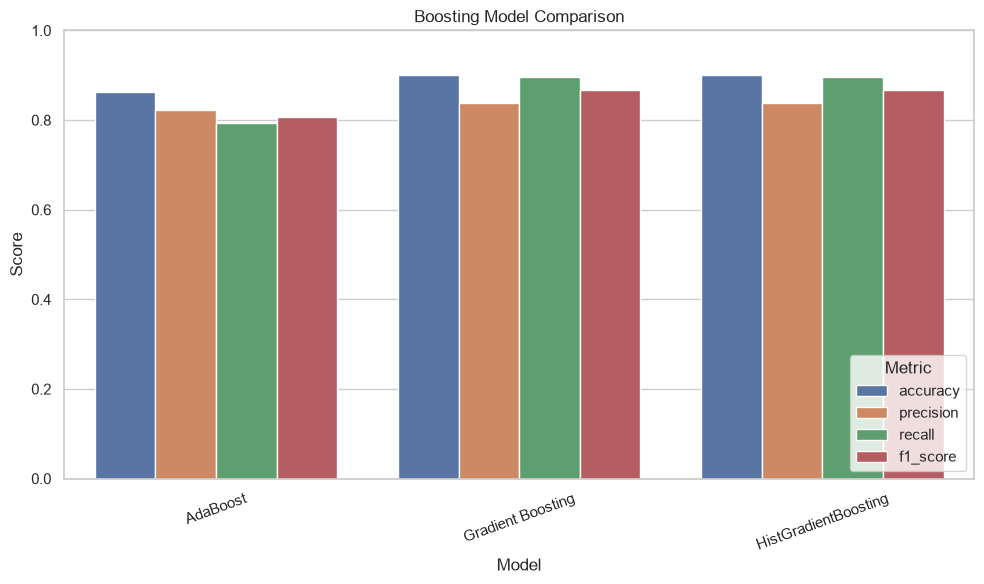

In [2]:
from IPython.display import display

boosting_comparison_fig = plot_model_comparison(
    boosting_result['metrics_df'], 'Boosting Model Comparison', config.PLOTS_DIR / 'boosting_comparison.png'
)
display(boosting_comparison_fig)

In [3]:
combined = compare_with_classification(classification_result['metrics_df'], boosting_result['metrics_df'])
combined

,model,accuracy,precision,recall,f1_score,roc_auc,cv_f1_mean
0,SVM,0.9125,0.866667,0.896552,0.881356,0.947262,0.869564
1,Random Forest,0.9000,0.838710,0.896552,0.866667,0.926640,0.853767
2,Gradient Boosting,0.9000,0.838710,0.896552,0.866667,0.951318,0.837112
3,KNN,0.9000,0.838710,0.896552,0.866667,0.930358,0.873870
4,HistGradientBoosting,0.9000,0.838710,0.896552,0.866667,0.937458,0.844260
5,Decision Tree,0.8625,0.764706,0.896552,0.825397,0.869844,0.811456
6,AdaBoost,0.8625,0.821429,0.793103,0.807018,0.937796,0.865376
7,Logistic Regression,0.8125,0.818182,0.620690,0.705882,0.905341,0.760605
